# Choice-Based Conjoint Analysis Workbook

This notebook is designed for basic users. It is part of a downloadable folder that contains the notebook, sample input CSV files, and example output files.

## Before You Start

The easiest way to run this notebook is with Anaconda, because Anaconda installs Python, Jupyter Notebook, and common data-analysis packages together.

Useful links:

- Download Anaconda: https://www.anaconda.com/download
- Anaconda installation guide: https://www.anaconda.com/docs/getting-started/anaconda/install
- Jupyter Notebook installation/help: https://jupyter.org/install

## How to Use This Notebook

1. Download and unzip the full folder.
2. Open Anaconda Navigator.
3. Launch Jupyter Notebook.
4. In Jupyter, open the downloaded folder.
5. Open this notebook: `Choice_Based_Conjoint_Analysis_Workbook.ipynb`.
6. Run the cells from top to bottom.
7. Review the printed tables and the CSV files saved in the `outputs/` folder.

## Input Files Used in This Example

- `Feature_specs.csv`: lists the features, feature type, number of levels, and optional min/max values.
- `Feature_template.csv`: lists the actual level values or labels for each feature.
- `Survey_response.csv`: contains participant responses in wide format, with columns such as `run_id_1`, `run_id_2`, and so on.

## What This Notebook Does

1. Generates a fractional factorial design and saves `fractional_factorial_design.csv`.
2. Uses the survey responses and generated design to fit a logistic-regression choice-based conjoint model.
3. Prints R2, p-values, significant features, coefficients, and the highest-probability feature combination.

The notebook only imports common Python analysis packages. It does **not** import any custom local package.

## Cell 1: Import Packages

Run this cell first. These are common Python data-analysis packages.

If a package is missing, install packages from a terminal opened in this folder:

```bash
pip install -r requirements.txt
```

If you are using Anaconda, most packages may already be installed.

In [1]:
# Main analysis packages only. No custom project/package imports are used.
from dataclasses import dataclass
from difflib import SequenceMatcher
from pathlib import Path

import itertools
import math
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import chi2
from IPython.display import display

Matplotlib is building the font cache; this may take a moment.


## Cell 2: File Locations and User Settings

Basic users usually only need to check this cell.

If the notebook and CSV files are in the same folder, you do not need to change the file paths.

Settings you may edit:

- `RUNS = None`: the notebook chooses a balanced number of design profiles automatically.
- `RUNS = 24`, `RUNS = 36`, etc.: use a specific number of profiles.
- `ALPHA = 0.05`: p-values below 0.05 are treated as statistically significant.
- `TOP_N_COMBINATIONS = 10`: number of best predicted combinations saved to CSV.

In [2]:
# This folder should contain the notebook and these input CSV files:
# - Feature_specs.csv
# - Feature_template.csv
# - Survey_response.csv
#
# In Jupyter, Path.cwd() is usually the folder where the notebook was opened.
BASE_DIR = Path.cwd()

# Input files. Basic users should keep these names unchanged.
FEATURE_SPECS_PATH = BASE_DIR / "Feature_specs.csv"
FEATURE_TEMPLATE_PATH = BASE_DIR / "Feature_template.csv"
SURVEY_RESPONSE_PATH = BASE_DIR / "Survey_response.csv"

# Files created by the fractional factorial design step.
FRACTIONAL_DESIGN_OUTPUT = BASE_DIR / "fractional_factorial_design.csv"
LEVELS_USED_OUTPUT = BASE_DIR / "levels_used.csv"

# Folder created by the conjoint analysis step.
CONJOINT_OUTPUT_DIR = BASE_DIR / "outputs"
CONJOINT_OUTPUT_DIR.mkdir(exist_ok=True)

# Design/model settings.
RUNS = None                # None means choose a practical balanced number of design profiles.
NUMERIC_CODING = "factor"  # "factor" estimates each numeric level; "linear" estimates one trend.
RANDOM_SEED = 42           # Keeps the generated design reproducible.
ALPHA = 0.05               # Significance threshold for p-values.
TOP_N_COMBINATIONS = 10    # Number of top predicted combinations to save.

print("Working folder:", BASE_DIR)
print("Design output:", FRACTIONAL_DESIGN_OUTPUT)
print("Conjoint outputs folder:", CONJOINT_OUTPUT_DIR)

Working folder: <project folder>
Design output: <project folder>/fractional_factorial_design.csv
Conjoint outputs folder: <project folder>/outputs


## Cell 3: Generate the Fractional Factorial Design

Run this cell after setting the file locations above.

This cell reads:

- `Feature_specs.csv`
- `Feature_template.csv`

It creates:

- `fractional_design_df`: a pandas DataFrame containing the selected fractional factorial design.
- `fractional_factorial_design.csv`: the same design saved as a CSV file.
- `levels_used_df`: a summary of the levels used for each feature.
- `levels_used.csv`: the same level summary saved as a CSV file.

For mixed-level designs, the notebook first builds the full factorial candidate set, then selects a smaller D-optimal fractional design for estimating main effects.

In [3]:
# -----------------------------
# Helper functions for design
# Users can run this full cell without editing the helper code.
# -----------------------------

CATEGORICAL_TYPES = {"categorical", "category", "nominal"}

SPEC_COLUMN_ALIASES = {
    "name": ("Features", "Parameter Name", "Feature", "Parameter"),
    "kind": ("Features_Type", "Parameter Type", "Feature Type", "Type"),
    "level_count": ("Level Number", "Levels", "Level Count", "Number of Levels"),
    "minimum": ("Minimum", "Min"),
    "maximum": ("Maximum", "Max"),
}


@dataclass(frozen=True)
class FeatureSpec:
    name: str
    kind: str
    level_count: int
    minimum: float | None
    maximum: float | None
    levels: tuple[str, ...]


def clean_header(value):
    return str(value).replace("\ufeff", "").strip()


def read_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [clean_header(column) for column in df.columns]
    return df


def normalized_column_name(value):
    return re.sub(r"[^a-z0-9]+", "", clean_header(value).lower())


def resolve_spec_columns(specs_df):
    # Allows user-friendly column names such as Features/Features_Type.
    normalized_to_original = {
        normalized_column_name(column): column for column in specs_df.columns
    }
    resolved = {}
    missing = []

    for field_name, aliases in SPEC_COLUMN_ALIASES.items():
        matched_column = None
        for alias in aliases:
            normalized_alias = normalized_column_name(alias)
            if normalized_alias in normalized_to_original:
                matched_column = normalized_to_original[normalized_alias]
                break
        if matched_column is None:
            missing.append("/".join(aliases))
        else:
            resolved[field_name] = matched_column

    if missing:
        raise ValueError(
            f"Feature_specs.csv is missing required columns: {missing}. "
            f"Available columns: {list(specs_df.columns)}"
        )
    return resolved


def comparable_name(value):
    # Makes column matching tolerant of spaces, underscores, punctuation, and units.
    text = clean_header(value).lower()
    text = text.replace("dollars", "$" ).replace("dollar", "$")
    text = re.sub(r"[^a-z0-9]+", "", text)
    for suffix in ("usd", "days", "day"):
        if text.endswith(suffix):
            text = text[: -len(suffix)]
    return text


def match_template_column(feature_name, template_columns):
    target = comparable_name(feature_name)
    scored = []
    for column in template_columns:
        candidate = comparable_name(column)
        if target == candidate:
            score = 1.0
        elif target in candidate or candidate in target:
            score = 0.95
        else:
            score = SequenceMatcher(None, target, candidate).ratio()
        scored.append((score, column))

    best_score, best_column = max(scored, key=lambda item: item[0])
    if best_score < 0.62:
        raise ValueError(f"Could not match feature {feature_name!r} to a template column.")
    return best_column


def optional_float(value):
    if pd.isna(value) or str(value).strip() == "":
        return None
    return float(value)


def normalize_kind(value):
    text = clean_header(value).lower()
    if text in {"continuous", "numeric"}:
        return "continuous"
    if text in {"discrete", "integer"}:
        return "discrete"
    if text in CATEGORICAL_TYPES:
        return "categorical"
    raise ValueError(f"Unsupported feature type: {value!r}")


def normalize_level(value, feature_type):
    if pd.isna(value):
        return ""
    text = str(value).strip()
    if text == "":
        return ""
    if feature_type in {"continuous", "discrete"}:
        numeric = float(text)
        return str(int(numeric)) if numeric.is_integer() else str(round(numeric, 6))
    return text


def unique_nonblank_levels(values, feature_type):
    levels = []
    seen = set()
    for value in values.tolist():
        level = normalize_level(value, feature_type)
        if level == "" or level in seen:
            continue
        levels.append(level)
        seen.add(level)

    if feature_type in {"continuous", "discrete"}:
        levels = sorted(levels, key=float)
    return levels


def generated_numeric_levels(name, feature_type, level_count, minimum, maximum):
    if minimum is None or maximum is None:
        raise ValueError(
            f"{name!r} needs explicit template levels or Minimum/Maximum values."
        )

    values = np.linspace(minimum, maximum, level_count)
    if feature_type == "discrete":
        values = np.rint(values)

    levels = []
    for value in values.tolist():
        level = str(int(value)) if float(value).is_integer() else str(round(float(value), 6))
        if level not in levels:
            levels.append(level)

    if len(levels) != level_count:
        raise ValueError(
            f"{name!r} generated {len(levels)} unique levels, but expected {level_count}."
        )
    return levels


def load_feature_specs(specs_path, template_path, strict=True):
    specs_df = read_csv(specs_path)
    template_df = read_csv(template_path)
    columns = resolve_spec_columns(specs_df)

    specs = []
    summary_rows = []

    for _, row in specs_df.iterrows():
        name = clean_header(row[columns["name"]])
        feature_type = normalize_kind(row[columns["kind"]])
        level_count = int(row[columns["level_count"]])
        minimum = optional_float(row[columns["minimum"]])
        maximum = optional_float(row[columns["maximum"]])

        template_column = match_template_column(name, list(template_df.columns))
        levels = unique_nonblank_levels(template_df[template_column], feature_type)

        if len(levels) != level_count:
            if feature_type in {"continuous", "discrete"} and len(levels) < level_count and not strict:
                levels = generated_numeric_levels(name, feature_type, level_count, minimum, maximum)
            else:
                raise ValueError(
                    f"{name!r} has {len(levels)} levels in Feature_template.csv, "
                    f"but Feature_specs.csv says {level_count}."
                )

        spec = FeatureSpec(
            name=name,
            kind=feature_type,
            level_count=level_count,
            minimum=minimum,
            maximum=maximum,
            levels=tuple(levels),
        )
        specs.append(spec)
        summary_rows.append({
            "Parameter Name": name,
            "Parameter Type": feature_type,
            "Level Number": level_count,
            "Levels Used": " | ".join(levels),
        })

    return specs, pd.DataFrame(summary_rows)


def full_factorial(specs):
    names = [spec.name for spec in specs]
    level_lists = [spec.levels for spec in specs]
    return pd.DataFrame(itertools.product(*level_lists), columns=names)


def effect_code(series, levels):
    # Effect coding creates k - 1 model columns for a feature with k levels.
    reference = levels[-1]
    coded = {}
    for level in levels[:-1]:
        column_name = f"{series.name}={level}"
        coded[column_name] = np.where(
            series == level,
            1.0,
            np.where(series == reference, -1.0, 0.0),
        )
    return pd.DataFrame(coded, index=series.index)


def build_design_model_matrix(candidates, specs, numeric_coding="factor"):
    parts = [pd.Series(1.0, index=candidates.index, name="Intercept")]

    for spec in specs:
        if spec.kind in {"continuous", "discrete"} and numeric_coding == "linear":
            values = pd.to_numeric(candidates[spec.name]).astype(float)
            if np.isclose(values.min(), values.max()):
                coded = pd.Series(0.0, index=candidates.index, name=spec.name)
            else:
                coded = 2.0 * (values - values.min()) / (values.max() - values.min()) - 1.0
                coded.name = spec.name
            parts.append(coded)
        else:
            parts.append(effect_code(candidates[spec.name], spec.levels))

    return pd.concat(parts, axis=1).astype(float)


def logdet_information(selected_x):
    information = selected_x.T @ selected_x
    sign, value = np.linalg.slogdet(information)
    return float(value) if sign > 0 else -np.inf


def random_start(x, n_runs, rng, starts=200):
    best_indices = None
    best_score = -np.inf
    best_rank = -1

    for _ in range(starts):
        indices = rng.choice(x.shape[0], size=n_runs, replace=False)
        selected_x = x[indices]
        rank = int(np.linalg.matrix_rank(selected_x))
        score = logdet_information(selected_x)
        if score > best_score or (not np.isfinite(best_score) and rank > best_rank):
            best_indices = indices
            best_score = score
            best_rank = rank

    if best_indices is None or not np.isfinite(best_score):
        raise ValueError("Could not find a full-rank starting design. Try increasing RUNS.")
    return best_indices, best_score


def default_run_count(n_candidates, n_terms, specs):
    # Prefer run counts that are divisible by each feature's number of levels.
    minimum_runs = min(n_candidates, max(2 * n_terms, n_terms + 4))
    level_lcm = 1
    for spec in specs:
        level_lcm = math.lcm(level_lcm, spec.level_count)
    balanced_runs = math.ceil(minimum_runs / level_lcm) * level_lcm
    practical_limit = math.ceil(minimum_runs * 1.5)
    return balanced_runs if balanced_runs <= n_candidates and balanced_runs <= practical_limit else minimum_runs


def d_optimal_fraction(candidates, model_matrix, n_runs, seed=42, starts=200, max_iter=100):
    x = model_matrix.to_numpy(dtype=float)
    n_candidates, n_terms = x.shape

    if n_runs > n_candidates:
        raise ValueError(f"RUNS cannot be larger than the full factorial size ({n_candidates}).")
    if n_runs < n_terms:
        raise ValueError(f"RUNS must be at least {n_terms} to estimate the main-effects model.")

    if n_runs == n_candidates:
        design = candidates.copy().reset_index(drop=True)
        design.insert(0, "run_id", np.arange(1, len(design) + 1))
        return design

    rng = np.random.default_rng(seed)
    selected, best_score = random_start(x, n_runs, rng, starts=starts)
    selected_set = set(selected.tolist())
    all_indices = set(range(n_candidates))

    # Exchange search: try replacing selected profiles with unselected profiles.
    for _ in range(max_iter):
        best_swap = None
        unselected = list(all_indices - selected_set)

        for position, out_index in enumerate(selected.tolist()):
            for in_index in unselected:
                trial = selected.copy()
                trial[position] = in_index
                score = logdet_information(x[trial])
                if score > best_score + 1e-10:
                    best_swap = (out_index, in_index, score, trial)
                    best_score = score

        if best_swap is None:
            break

        out_index, in_index, _, selected = best_swap
        selected_set.remove(out_index)
        selected_set.add(in_index)

    design = candidates.iloc[selected].copy().reset_index(drop=True)
    design.insert(0, "run_id", np.arange(1, len(design) + 1))
    return design


# -----------------------------
# Run the fractional factorial design
# This is the part that reads the input CSVs and writes the design outputs.
# -----------------------------

feature_specs, levels_used_df = load_feature_specs(
    FEATURE_SPECS_PATH,
    FEATURE_TEMPLATE_PATH,
    strict=True,
)

full_factorial_df = full_factorial(feature_specs)
design_x = build_design_model_matrix(full_factorial_df, feature_specs, numeric_coding=NUMERIC_CODING)

n_terms = design_x.shape[1]
n_candidates = len(full_factorial_df)
n_runs = RUNS if RUNS is not None else default_run_count(n_candidates, n_terms, feature_specs)

fractional_design_df = d_optimal_fraction(
    candidates=full_factorial_df,
    model_matrix=design_x,
    n_runs=n_runs,
    seed=RANDOM_SEED,
)

fractional_design_df.to_csv(FRACTIONAL_DESIGN_OUTPUT, index=False)
levels_used_df.to_csv(LEVELS_USED_OUTPUT, index=False)

print(f"Features: {len(feature_specs)}")
print(f"Full factorial profiles: {n_candidates}")
print(f"Main-effects terms including intercept: {n_terms}")
print(f"Fractional design profiles: {len(fractional_design_df)}")
print(f"Saved design CSV to: {FRACTIONAL_DESIGN_OUTPUT}")
print(f"Saved levels CSV to: {LEVELS_USED_OUTPUT}")

display(levels_used_df)
display(fractional_design_df.head())

Features: 6
Full factorial profiles: 648
Main-effects terms including intercept: 13
Fractional design profiles: 36
Saved design CSV to: <project folder>/fractional_factorial_design.csv
Saved levels CSV to: <project folder>/levels_used.csv


,Parameter Name,Parameter Type,Level Number,Levels Used
0,Monthly_membership_fee_$,continuous,4,50 | 80 | 130 | 200
1,Time_to_next_available_appointment_days,discrete,3,3 | 7 | 14
2,Out-of-pocket_cost_per_visit_$,continuous,3,25 | 75 | 150
3,Care_coordination_&_follow-up,categorical,3,No portal follow-up | Portal for results and r...
4,Visit_access_options,categorical,3,Weekday daytime only | Evening appointments av...
5,Care_Provider_Facility,categorical,2,Hospital | Local clinic


,run_id,Monthly_membership_fee_$,Time_to_next_available_appointment_days,Out-of-pocket_cost_per_visit_$,Care_coordination_&_follow-up,Visit_access_options,Care_Provider_Facility
0,1,80,7,75,Portal for results and refills,Evening appointments available,Hospital
1,2,130,7,25,No portal follow-up,Evening appointments available,Local clinic
2,3,80,14,75,No portal follow-up,Weekday daytime only,Local clinic
3,4,200,7,25,No portal follow-up,Evening + weekend + telehealth available,Hospital
4,5,50,7,75,Portal for results and refills,Evening + weekend + telehealth available,Hospital


## Cell 4: Choice-Based Conjoint Analysis

Run this cell after Cell 3 has created `fractional_factorial_design.csv` and `levels_used.csv`.

This cell reads:

- `Survey_response.csv`
- `fractional_factorial_design.csv`
- `levels_used.csv`

It then:

1. Structures a new model dataset with the binary response/outcome and all feature levels.
2. Fits a logistic regression model.
3. Prints McFadden pseudo R2, the overall model p-value, and significant features.
4. Prints coefficients for every feature and level.
5. Finds the feature combination with the highest predicted probability.

Important note for beginners: logistic regression needs a reference level for each feature. This notebook uses the first level listed in `levels_used.csv` as the reference level. Reference levels appear in the coefficient table with coefficient `0`.

In [4]:
# -----------------------------
# Helper functions for conjoint analysis
# Basic users can run this full cell without editing the helper code.
# -----------------------------

OUTCOME_COLUMN = "outcome"
RUN_ID_COLUMN = "run_id"


def safe_name(value):
    text = re.sub(r"[^A-Za-z0-9]+", "_", str(value).strip())
    return text.strip("_") or "value"


def indicator_name(feature, level):
    return f"{safe_name(feature)}__{safe_name(level)}"


def load_level_specs_from_csv(levels_path):
    levels_df = read_csv(levels_path)
    specs = []

    for _, row in levels_df.iterrows():
        feature = clean_header(row["Parameter Name"])
        feature_type = normalize_kind(row["Parameter Type"])
        levels = tuple(
            normalize_level(level, feature_type)
            for level in str(row["Levels Used"]).split("|")
            if str(level).strip() != ""
        )
        expected_count = int(row["Level Number"])
        if len(levels) != expected_count:
            raise ValueError(
                f"{feature!r} has {len(levels)} levels in levels_used.csv, "
                f"but Level Number says {expected_count}."
            )
        specs.append(FeatureSpec(feature, feature_type, expected_count, None, None, levels))

    return specs


def find_participant_column(responses_df):
    for candidate in ["Participant_ID", "participant_id", "Participant", "Respondent_ID"]:
        if candidate in responses_df.columns:
            return candidate
    return responses_df.columns[0]


def response_run_columns(responses_df):
    columns = [column for column in responses_df.columns if re.fullmatch(r"run_id_\d+", str(column))]
    if not columns:
        raise ValueError("Survey_response.csv must contain columns named run_id_1, run_id_2, etc.")
    return sorted(columns, key=lambda column: int(str(column).split("_")[-1]))


def build_model_dataset(responses_df, design_df, specs):
    participant_col = find_participant_column(responses_df)
    run_columns = response_run_columns(responses_df)

    long_responses = responses_df.melt(
        id_vars=[participant_col],
        value_vars=run_columns,
        var_name="response_column",
        value_name=OUTCOME_COLUMN,
    )
    long_responses[RUN_ID_COLUMN] = (
        long_responses["response_column"].str.extract(r"run_id_(\d+)", expand=False).astype(int)
    )
    long_responses = long_responses.drop(columns=["response_column"])
    long_responses[OUTCOME_COLUMN] = pd.to_numeric(long_responses[OUTCOME_COLUMN], errors="raise").astype(int)

    invalid_values = sorted(set(long_responses[OUTCOME_COLUMN]) - {0, 1})
    if invalid_values:
        raise ValueError(f"Outcome values must be 0/1 only. Found: {invalid_values}")

    design_df = design_df.copy()
    design_df[RUN_ID_COLUMN] = pd.to_numeric(design_df[RUN_ID_COLUMN], errors="raise").astype(int)

    feature_columns = [spec.name for spec in specs]
    for spec in specs:
        design_df[spec.name] = design_df[spec.name].map(lambda value, t=spec.kind: normalize_level(value, t))

    missing_run_ids = sorted(set(long_responses[RUN_ID_COLUMN]) - set(design_df[RUN_ID_COLUMN]))
    if missing_run_ids:
        raise ValueError(f"Survey responses refer to run IDs missing from the design: {missing_run_ids}")

    model_dataset = long_responses.merge(
        design_df[[RUN_ID_COLUMN, *feature_columns]],
        on=RUN_ID_COLUMN,
        how="left",
        validate="many_to_one",
    )
    model_dataset = model_dataset.sort_values([participant_col, RUN_ID_COLUMN]).reset_index(drop=True)
    return model_dataset, participant_col


def encode_for_logistic_regression(model_dataset, specs):
    encoded_df = model_dataset.copy()
    all_indicator_columns = []
    model_columns = []
    reference_levels = {}

    for spec in specs:
        reference_level = spec.levels[0]
        reference_levels[spec.name] = reference_level

        for index, level in enumerate(spec.levels):
            column = indicator_name(spec.name, level)
            encoded_df[column] = (encoded_df[spec.name].astype(str) == level).astype(int)
            all_indicator_columns.append(column)

            # The first level is the reference level, so it is not included in the regression matrix.
            if index > 0:
                model_columns.append(column)

    return encoded_df, all_indicator_columns, model_columns, reference_levels


def fit_logistic_regression(encoded_df, model_columns, participant_col):
    y = encoded_df[OUTCOME_COLUMN].astype(float)
    x = encoded_df[model_columns].astype(float)
    x = sm.add_constant(x, has_constant="add")

    model = sm.GLM(y, x, family=sm.families.Binomial())

    # Clustered standard errors account for repeated answers from the same participant.
    result = model.fit(
        maxiter=200,
        cov_type="cluster",
        cov_kwds={"groups": encoded_df[participant_col]},
    )

    null_x = pd.DataFrame({"const": np.ones(len(y))}, index=encoded_df.index)
    null_result = sm.GLM(y, null_x, family=sm.families.Binomial()).fit(maxiter=200)
    return result, null_result


def make_metrics_table(result, null_result, model_dataset, participant_col, n_features):
    log_likelihood = float(result.llf)
    null_log_likelihood = float(null_result.llf)
    lr_chi_square = 2.0 * (log_likelihood - null_log_likelihood)
    lr_df = int(result.df_model)
    lr_p_value = float(chi2.sf(lr_chi_square, lr_df))
    pseudo_r2 = float(1.0 - (log_likelihood / null_log_likelihood))

    return pd.DataFrame([{
        "n_observations": len(model_dataset),
        "n_participants": model_dataset[participant_col].nunique(),
        "n_profiles": model_dataset[RUN_ID_COLUMN].nunique(),
        "n_features": n_features,
        "positive_outcomes": int(model_dataset[OUTCOME_COLUMN].sum()),
        "positive_rate": float(model_dataset[OUTCOME_COLUMN].mean()),
        "log_likelihood": log_likelihood,
        "null_log_likelihood": null_log_likelihood,
        "likelihood_ratio_chi_square": lr_chi_square,
        "likelihood_ratio_df": lr_df,
        "likelihood_ratio_p_value": lr_p_value,
        "mcfadden_pseudo_r2": pseudo_r2,
        "aic": float(result.aic),
        "bic": float(getattr(result, "bic_llf", result.bic)),
    }])


def make_coefficient_table(result, specs, reference_levels, alpha=0.05):
    conf_int = result.conf_int(alpha=alpha)
    rows = []

    for spec in specs:
        reference_level = reference_levels[spec.name]
        for level in spec.levels:
            column = indicator_name(spec.name, level)
            is_reference = level == reference_level

            if is_reference:
                coefficient = 0.0
                std_error = np.nan
                z_value = np.nan
                p_value = np.nan
                ci_lower = np.nan
                ci_upper = np.nan
            else:
                coefficient = float(result.params[column])
                std_error = float(result.bse[column])
                z_value = float(result.tvalues[column])
                p_value = float(result.pvalues[column])
                ci_lower = float(conf_int.loc[column, 0])
                ci_upper = float(conf_int.loc[column, 1])

            rows.append({
                "feature": spec.name,
                "level": level,
                "reference_level": reference_level,
                "is_reference": is_reference,
                "coefficient": coefficient,
                "std_error": std_error,
                "z_value": z_value,
                "p_value": p_value,
                "odds_ratio": float(np.exp(coefficient)),
                "ci_lower": ci_lower,
                "ci_upper": ci_upper,
                "odds_ratio_ci_lower": float(np.exp(ci_lower)) if not np.isnan(ci_lower) else np.nan,
                "odds_ratio_ci_upper": float(np.exp(ci_upper)) if not np.isnan(ci_upper) else np.nan,
                "significant": False if is_reference or np.isnan(p_value) else bool(p_value < alpha),
            })

    return pd.DataFrame(rows)


def make_feature_significance_table(result, specs, alpha=0.05):
    # Joint Wald test: asks whether a feature matters overall, across all non-reference levels.
    cov = result.cov_params()
    rows = []

    for spec in specs:
        columns = [indicator_name(spec.name, level) for level in spec.levels[1:]]
        beta = result.params[columns].to_numpy(dtype=float)
        covariance = cov.loc[columns, columns].to_numpy(dtype=float)
        wald_chi_square = float(beta.T @ np.linalg.pinv(covariance) @ beta)
        degrees_of_freedom = len(columns)
        p_value = float(chi2.sf(wald_chi_square, degrees_of_freedom))
        rows.append({
            "feature": spec.name,
            "reference_level": spec.levels[0],
            "degrees_of_freedom": degrees_of_freedom,
            "wald_chi_square": wald_chi_square,
            "p_value": p_value,
            "significant": bool(p_value < alpha),
        })

    return pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)


def predict_all_feature_combinations(result, specs, model_columns):
    feature_names = [spec.name for spec in specs]
    all_levels = [spec.levels for spec in specs]
    combinations_df = pd.DataFrame(itertools.product(*all_levels), columns=feature_names)

    encoded_combinations = combinations_df.copy()
    for spec in specs:
        for level in spec.levels[1:]:
            column = indicator_name(spec.name, level)
            encoded_combinations[column] = (encoded_combinations[spec.name].astype(str) == level).astype(float)

    x = sm.add_constant(encoded_combinations[model_columns].astype(float), has_constant="add")
    x = x[result.params.index]
    combinations_df["predicted_probability"] = result.predict(x)
    combinations_df["predicted_odds"] = combinations_df["predicted_probability"] / (1.0 - combinations_df["predicted_probability"])
    return combinations_df.sort_values("predicted_probability", ascending=False).reset_index(drop=True)


# -----------------------------
# Run the choice-based conjoint analysis
# This part creates the model-ready dataset, fits logistic regression, and saves outputs.
# -----------------------------

survey_response_df = read_csv(SURVEY_RESPONSE_PATH)
design_for_analysis_df = read_csv(FRACTIONAL_DESIGN_OUTPUT)
analysis_specs = load_level_specs_from_csv(LEVELS_USED_OUTPUT)

model_dataset_df, participant_col = build_model_dataset(
    survey_response_df,
    design_for_analysis_df,
    analysis_specs,
)

encoded_model_dataset_df, all_indicator_columns, model_columns, reference_levels = encode_for_logistic_regression(
    model_dataset_df,
    analysis_specs,
)

logistic_result, null_logistic_result = fit_logistic_regression(
    encoded_model_dataset_df,
    model_columns,
    participant_col,
)

metrics_df = make_metrics_table(
    logistic_result,
    null_logistic_result,
    model_dataset_df,
    participant_col,
    n_features=len(analysis_specs),
)

feature_significance_df = make_feature_significance_table(
    logistic_result,
    analysis_specs,
    alpha=ALPHA,
)

coefficients_df = make_coefficient_table(
    logistic_result,
    analysis_specs,
    reference_levels,
    alpha=ALPHA,
)

top_combinations_df = predict_all_feature_combinations(
    logistic_result,
    analysis_specs,
    model_columns,
)

best_combination_df = top_combinations_df.head(1).copy()

# Save all requested outputs.
model_dataset_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_model_dataset.csv", index=False)
encoded_model_dataset_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_encoded_dataset.csv", index=False)
metrics_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_model_metrics.csv", index=False)
feature_significance_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_feature_significance.csv", index=False)
feature_significance_df.loc[feature_significance_df["significant"]].to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_significant_features.csv",
    index=False,
)
coefficients_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_coefficients.csv", index=False)
coefficients_df.loc[coefficients_df["significant"]].to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_significant_levels.csv",
    index=False,
)
best_combination_df.to_csv(CONJOINT_OUTPUT_DIR / "conjoint_best_combination.csv", index=False)
top_combinations_df.head(TOP_N_COMBINATIONS).to_csv(
    CONJOINT_OUTPUT_DIR / "conjoint_top_combinations.csv",
    index=False,
)

# Print the key outputs requested in the prompt.
metrics = metrics_df.iloc[0]
significant_feature_names = feature_significance_df.loc[
    feature_significance_df["significant"], "feature"
].tolist()

print("Choice-based conjoint analysis complete")
print(f"Model dataset rows: {int(metrics['n_observations'])}")
print(f"Participants: {int(metrics['n_participants'])}")
print(f"Profiles: {int(metrics['n_profiles'])}")
print(f"McFadden pseudo R2: {metrics['mcfadden_pseudo_r2']:.6f}")
print(f"Overall model p-value: {metrics['likelihood_ratio_p_value']:.6g}")
print("Significant features:", ", ".join(significant_feature_names) if significant_feature_names else "none")
print(f"\nFiles saved to: {CONJOINT_OUTPUT_DIR}")

print("\n1. Model dataset with response/outcome and feature levels")
display(model_dataset_df.head())

print("\n2. Model metrics")
display(metrics_df)

print("\n3. Feature significance")
display(feature_significance_df)

print("\n4. Coefficients for every feature and level")
display(coefficients_df)

print("\n5. Feature combination with highest predicted probability")
display(best_combination_df)

Choice-based conjoint analysis complete
Model dataset rows: 7200
Participants: 200
Profiles: 36
McFadden pseudo R2: 0.003107
Overall model p-value: 0.0333327
Significant features: Time_to_next_available_appointment_days

Files saved to: <project folder>/outputs

1. Model dataset with response/outcome and feature levels


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the log-likelihood version using the `bic_llf` attribute. You can suppress this message by calling statsmodels.genmod.generalized_linear_model.SET_USE_BIC_LLF with True to get the LLF-based version now or False to retainthe deviance version.
  warnings.warn(


,Participant_ID,outcome,run_id,Monthly_membership_fee_$,Time_to_next_available_appointment_days,Out-of-pocket_cost_per_visit_$,Care_coordination_&_follow-up,Visit_access_options,Care_Provider_Facility
0,1,0,1,80,7,75,Portal for results and refills,Evening appointments available,Hospital
1,1,0,2,130,7,25,No portal follow-up,Evening appointments available,Local clinic
2,1,1,3,80,14,75,No portal follow-up,Weekday daytime only,Local clinic
3,1,0,4,200,7,25,No portal follow-up,Evening + weekend + telehealth available,Hospital
4,1,0,5,50,7,75,Portal for results and refills,Evening + weekend + telehealth available,Hospital



2. Model metrics


,n_observations,n_participants,n_profiles,n_features,positive_outcomes,positive_rate,log_likelihood,null_log_likelihood,likelihood_ratio_chi_square,likelihood_ratio_df,likelihood_ratio_p_value,mcfadden_pseudo_r2,aic,bic
0,7200,200,36,6,1441,0.200139,-3593.086241,-3604.28331,22.394137,12,0.033333,0.003107,7212.172482,7301.636354



3. Feature significance


,feature,reference_level,degrees_of_freedom,wald_chi_square,p_value,significant
0,Time_to_next_available_appointment_days,3,2,8.067217,0.017710,True
1,Monthly_membership_fee_$,50,3,5.875924,0.117805,False
2,Out-of-pocket_cost_per_visit_$,25,2,3.726167,0.155193,False
3,Care_coordination_&_follow-up,No portal follow-up,2,3.443548,0.178749,False
4,Visit_access_options,Weekday daytime only,2,1.947034,0.377752,False
5,Care_Provider_Facility,Hospital,1,0.172013,0.678329,False



4. Coefficients for every feature and level


,feature,level,reference_level,is_reference,coefficient,std_error,z_value,p_value,odds_ratio,ci_lower,ci_upper,odds_ratio_ci_lower,odds_ratio_ci_upper,significant
0,Monthly_membership_fee_$,50,50,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False
1,Monthly_membership_fee_$,80,50,False,0.061626,0.076753,0.802914,0.422025,1.063564,-0.088807,0.212058,0.915022,1.236220,False
2,Monthly_membership_fee_$,130,50,False,-0.014259,0.087459,-0.163042,0.870486,0.985842,-0.185676,0.157157,0.830543,1.170179,False
3,Monthly_membership_fee_$,200,50,False,0.168788,0.084547,1.996377,0.045893,1.183869,0.003079,0.334497,1.003083,1.397237,True
4,Time_to_next_available_appointment_days,3,3,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False
5,Time_to_next_available_appointment_days,7,3,False,-0.135983,0.069675,-1.951674,0.050977,0.872858,-0.272543,0.000578,0.761441,1.000578,False
6,Time_to_next_available_appointment_days,14,3,False,-0.173351,0.066922,-2.590341,0.009588,0.840842,-0.304516,-0.042186,0.737480,0.958691,True
7,Out-of-pocket_cost_per_visit_$,25,25,True,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,False
8,Out-of-pocket_cost_per_visit_$,75,25,False,0.154158,0.083595,1.844114,0.065167,1.166675,-0.009684,0.318000,0.990362,1.374376,False
9,Out-of-pocket_cost_per_visit_$,150,25,False,0.044430,0.067563,0.657620,0.510782,1.045432,-0.087990,0.176851,0.915770,1.193453,False



5. Feature combination with highest predicted probability


,Monthly_membership_fee_$,Time_to_next_available_appointment_days,Out-of-pocket_cost_per_visit_$,Care_coordination_&_follow-up,Visit_access_options,Care_Provider_Facility,predicted_probability,predicted_odds
0,200,3,75,Portal for results and refills,Evening + weekend + telehealth available,Hospital,0.27065,0.371084


## Cell 5: Visual Results and Optimum Feature Combination

Run this final cell after the logistic regression cell.

This cell creates beginner-friendly visual summaries:

1. **Coefficient plot by feature and level**: shows whether each level increases or decreases the probability of being chosen compared with the reference level.
2. **Feature p-value plot**: shows which features are statistically significant overall.
3. **Top combinations plot**: shows the highest predicted feature combinations.
4. **Optimum combination table**: lists the single feature-level combination with the highest predicted probability.

The plots are saved as PNG files in the `outputs/` folder.

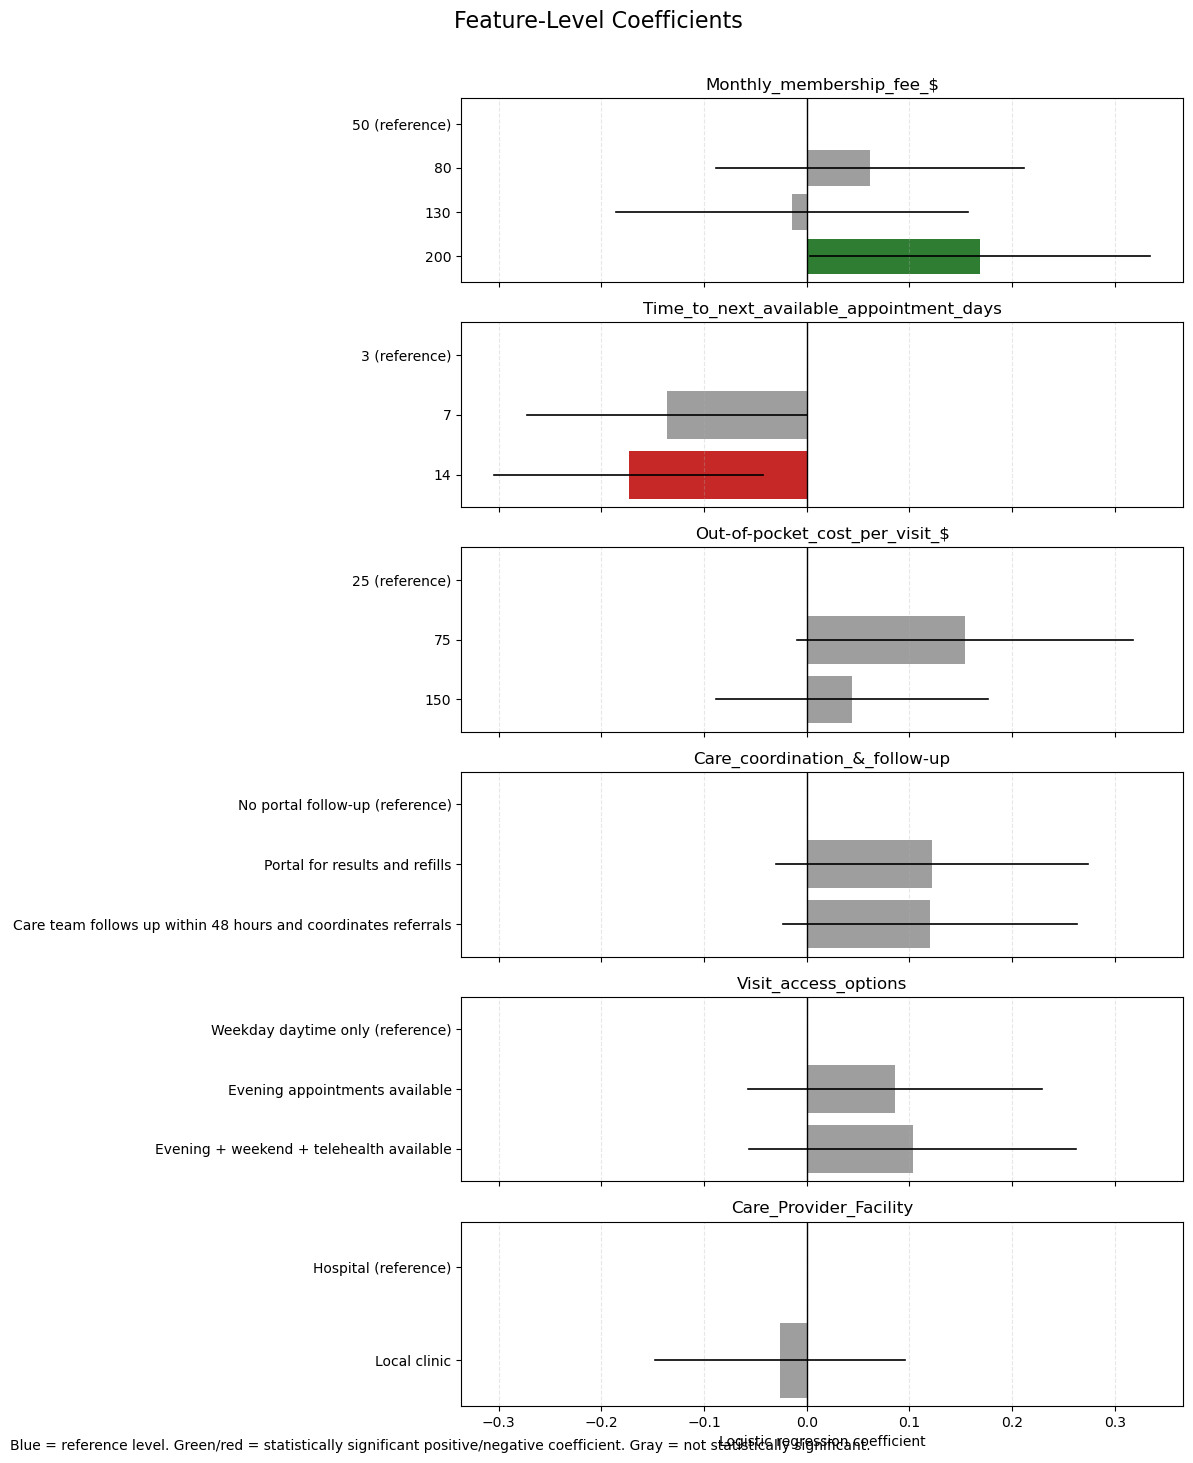

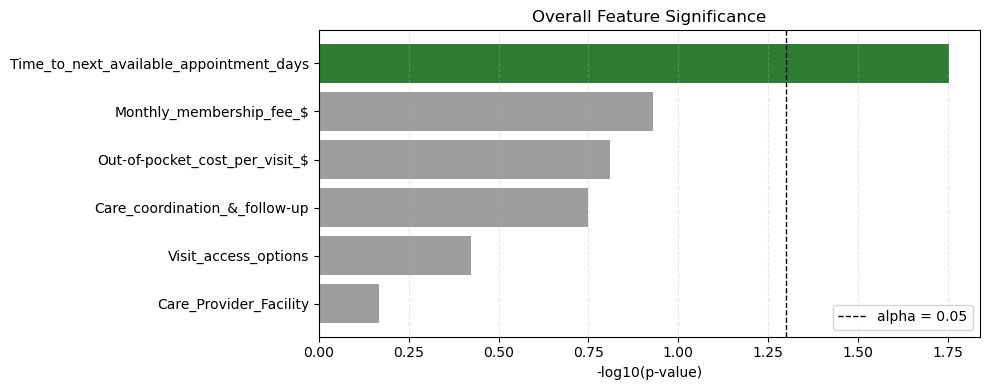

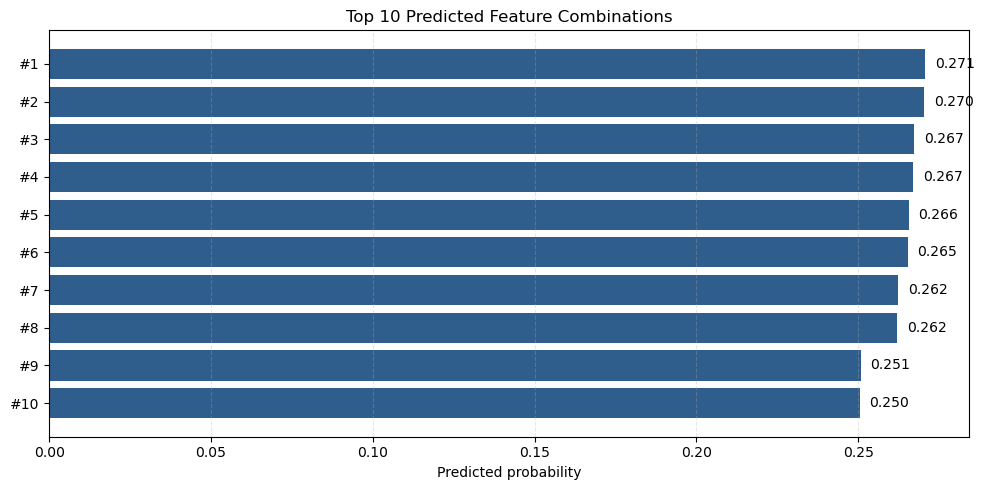

Saved coefficient plot to: <project folder>/outputs/conjoint_coefficients_by_feature.png
Saved feature p-value plot to: <project folder>/outputs/conjoint_feature_p_values.png
Saved top combinations plot to: <project folder>/outputs/conjoint_top_combinations.png
Saved optimum combination table to: <project folder>/outputs/conjoint_optimum_combination_long.csv

Most optimum feature-level combination
Predicted probability: 0.270650
Predicted odds: 0.371084


,feature,optimum_level,predicted_probability_for_combination,predicted_odds_for_combination
0,Monthly_membership_fee_$,200,0.27065,0.371084
1,Time_to_next_available_appointment_days,3,0.27065,0.371084
2,Out-of-pocket_cost_per_visit_$,75,0.27065,0.371084
3,Care_coordination_&_follow-up,Portal for results and refills,0.27065,0.371084
4,Visit_access_options,Evening + weekend + telehealth available,0.27065,0.371084
5,Care_Provider_Facility,Hospital,0.27065,0.371084



Top predicted combinations with details


,combination_number,predicted_probability,predicted_odds,combination_details
0,#1,0.270650,0.371084,Monthly_membership_fee_$: 200 | Time_to_next_a...
1,#2,0.270316,0.370457,Monthly_membership_fee_$: 200 | Time_to_next_a...
2,#3,0.267327,0.364865,Monthly_membership_fee_$: 200 | Time_to_next_a...
3,#4,0.266995,0.364248,Monthly_membership_fee_$: 200 | Time_to_next_a...
4,#5,0.265588,0.361633,Monthly_membership_fee_$: 200 | Time_to_next_a...
5,#6,0.265258,0.361021,Monthly_membership_fee_$: 200 | Time_to_next_a...
6,#7,0.262304,0.355571,Monthly_membership_fee_$: 200 | Time_to_next_a...
7,#8,0.261976,0.354970,Monthly_membership_fee_$: 200 | Time_to_next_a...
8,#9,0.250782,0.334726,Monthly_membership_fee_$: 200 | Time_to_next_a...
9,#10,0.250465,0.334160,Monthly_membership_fee_$: 200 | Time_to_next_a...


In [5]:
# -----------------------------
# Visual results and optimum feature combination
# -----------------------------

# Colors used in the coefficient plot.
REFERENCE_COLOR = "#2F5D8C"
POSITIVE_SIGNIFICANT_COLOR = "#2E7D32"
NEGATIVE_SIGNIFICANT_COLOR = "#C62828"
NOT_SIGNIFICANT_COLOR = "#9E9E9E"


def coefficient_color(row):
    if row["is_reference"]:
        return REFERENCE_COLOR
    if not row["significant"]:
        return NOT_SIGNIFICANT_COLOR
    if row["coefficient"] >= 0:
        return POSITIVE_SIGNIFICANT_COLOR
    return NEGATIVE_SIGNIFICANT_COLOR


# 1. Plot coefficients for every feature and level.
# Reference levels are shown at coefficient 0.
coefficient_plot_df = coefficients_df.copy()
coefficient_plot_df["plot_label"] = coefficient_plot_df.apply(
    lambda row: f"{row['level']}" + (" (reference)" if row["is_reference"] else ""),
    axis=1,
)

features_in_order = [spec.name for spec in analysis_specs]
fig_height = max(4, 2.4 * len(features_in_order))
fig, axes = plt.subplots(
    nrows=len(features_in_order),
    ncols=1,
    figsize=(12, fig_height),
    sharex=True,
)
if len(features_in_order) == 1:
    axes = [axes]

for ax, feature in zip(axes, features_in_order):
    feature_df = coefficient_plot_df.loc[coefficient_plot_df["feature"] == feature].copy()
    y_positions = np.arange(len(feature_df))
    colors = [coefficient_color(row) for _, row in feature_df.iterrows()]

    ax.barh(y_positions, feature_df["coefficient"], color=colors)

    # Add confidence intervals for non-reference levels.
    for y, (_, row) in zip(y_positions, feature_df.iterrows()):
        if not row["is_reference"] and not pd.isna(row["ci_lower"]):
            ax.plot([row["ci_lower"], row["ci_upper"]], [y, y], color="black", linewidth=1.2)

    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(feature_df["plot_label"])
    ax.invert_yaxis()
    ax.set_title(feature)
    ax.grid(axis="x", linestyle="--", alpha=0.3)

axes[-1].set_xlabel("Logistic regression coefficient")
fig.suptitle("Feature-Level Coefficients", fontsize=16, y=1.01)
fig.text(
    0.01,
    0.01,
    "Blue = reference level. Green/red = statistically significant positive/negative coefficient. Gray = not statistically significant.",
    fontsize=10,
)
fig.tight_layout()
coefficient_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_coefficients_by_feature.png"
fig.savefig(coefficient_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 2. Plot feature-level p-values from the joint Wald tests.
feature_pvalue_plot_df = feature_significance_df.copy().sort_values("p_value", ascending=True)
feature_pvalue_plot_df["minus_log10_p"] = -np.log10(feature_pvalue_plot_df["p_value"].clip(lower=1e-300))
significance_line = -np.log10(ALPHA)

fig, ax = plt.subplots(figsize=(10, max(4, 0.55 * len(feature_pvalue_plot_df))))
bar_colors = np.where(feature_pvalue_plot_df["significant"], POSITIVE_SIGNIFICANT_COLOR, NOT_SIGNIFICANT_COLOR)
ax.barh(feature_pvalue_plot_df["feature"], feature_pvalue_plot_df["minus_log10_p"], color=bar_colors)
ax.axvline(significance_line, color="black", linestyle="--", linewidth=1, label=f"alpha = {ALPHA}")
ax.invert_yaxis()
ax.set_xlabel("-log10(p-value)")
ax.set_title("Overall Feature Significance")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.3)
fig.tight_layout()
feature_pvalue_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_feature_p_values.png"
fig.savefig(feature_pvalue_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 3. Create a readable label for each top predicted combination.
def combination_label(row, specs):
    pieces = []
    for spec in specs:
        pieces.append(f"{spec.name}: {row[spec.name]}")
    return " | ".join(pieces)


top_plot_df = top_combinations_df.head(TOP_N_COMBINATIONS).copy()
top_plot_df["combination_number"] = [f"#{i}" for i in range(1, len(top_plot_df) + 1)]
top_plot_df["combination_details"] = top_plot_df.apply(
    lambda row: combination_label(row, analysis_specs),
    axis=1,
)

fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(top_plot_df))))
ax.barh(top_plot_df["combination_number"], top_plot_df["predicted_probability"], color="#2F5D8C")
ax.invert_yaxis()
ax.set_xlabel("Predicted probability")
ax.set_title(f"Top {TOP_N_COMBINATIONS} Predicted Feature Combinations")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for y, probability in enumerate(top_plot_df["predicted_probability"]):
    ax.text(probability + 0.003, y, f"{probability:.3f}", va="center")
fig.tight_layout()
top_combinations_plot_path = CONJOINT_OUTPUT_DIR / "conjoint_top_combinations.png"
fig.savefig(top_combinations_plot_path, dpi=200, bbox_inches="tight")
plt.show()


# 4. Output the single optimum feature-level combination in a beginner-friendly format.
best_row = best_combination_df.iloc[0]
optimum_combination_df = pd.DataFrame([
    {
        "feature": spec.name,
        "optimum_level": best_row[spec.name],
        "predicted_probability_for_combination": best_row["predicted_probability"],
        "predicted_odds_for_combination": best_row["predicted_odds"],
    }
    for spec in analysis_specs
])

optimum_combination_path = CONJOINT_OUTPUT_DIR / "conjoint_optimum_combination_long.csv"
optimum_combination_df.to_csv(optimum_combination_path, index=False)

print("Saved coefficient plot to:", coefficient_plot_path)
print("Saved feature p-value plot to:", feature_pvalue_plot_path)
print("Saved top combinations plot to:", top_combinations_plot_path)
print("Saved optimum combination table to:", optimum_combination_path)

print("\nMost optimum feature-level combination")
print(f"Predicted probability: {best_row['predicted_probability']:.6f}")
print(f"Predicted odds: {best_row['predicted_odds']:.6f}")
display(optimum_combination_df)

print("\nTop predicted combinations with details")
display(top_plot_df[["combination_number", "predicted_probability", "predicted_odds", "combination_details"]])

## What to Download or Share

After running the notebook, the most important output files are:

- `fractional_factorial_design.csv`: generated fractional factorial design.
- `levels_used.csv`: level summary used by the design and model.
- `outputs/conjoint_model_dataset.csv`: model-ready long dataset with outcome and feature levels.
- `outputs/conjoint_model_metrics.csv`: R2 and model p-value.
- `outputs/conjoint_feature_significance.csv`: p-values for each feature.
- `outputs/conjoint_coefficients.csv`: coefficient table for every feature and level.
- `outputs/conjoint_best_combination.csv`: best combination in one-row format.
- `outputs/conjoint_optimum_combination_long.csv`: best combination in easy-to-read long format.
- `outputs/conjoint_coefficients_by_feature.png`: visual coefficient plot by feature and level.
- `outputs/conjoint_feature_p_values.png`: visual p-value plot for features.
- `outputs/conjoint_top_combinations.png`: visual plot of top predicted combinations.

## Beginner Interpretation Notes

- A p-value below `0.05` is commonly treated as statistically significant.
- McFadden pseudo R2 is used for logistic regression. It is not interpreted the same way as ordinary linear-regression R2.
- Positive coefficients mean that level is associated with higher probability of being chosen compared with the reference level.
- Negative coefficients mean that level is associated with lower probability of being chosen compared with the reference level.
- The best combination is the combination of feature levels with the highest model-predicted probability.